# Chapter 1: Data - Data Preprocessing & Feature Engineering Pipeline

This workbook represents the core data extraction, preprocessing, and feature engineering phase of the analytical pipeline. Its primary function is to query raw, heuristically clustered blockchain transaction data from a local MySQL database and transform it into a robust, mathematically smoothed feature matrix optimized for machine learning classification.

Because Bitcoin entities often suffer from transaction sparsity and clustering inaccuracies, this pipeline applies rigorous data validation and temporal noise filtration prior to feature generation. 

**Key Pipeline Stages:**
1. **Data Extraction & Entity Resolution:** Retrieves clustered entities while automatically filtering out known institutional wallets, miners, and exchanges to ensure the dataset represents individual human behavior.
2. **Temporal Noise Filtration:** Identifies and excludes entities exhibiting "temporal drift"—a heuristic failure where overlapping addresses report conflicting time zones, artificially blending distinct circadian rhythms.
3. **Temporal Standardization:** Extracts transaction mempool entry times and standardizes them to UTC+0 based on regional offsets to create a uniform baseline.
4. **Diurnal Feature Engineering:** Constructs 24-hour transaction activity distributions. Applies Bayesian Normalization (Laplace smoothing) to heavily mitigate the impact of data sparsity limits in low-volume hours.
5. **Behavioral Subset Analysis:** Engineers supplementary multidimensional features, including entity lifespan, minimum 5-hour inactivity windows, weekday/weekend segmentation, and behavioral Daylight Saving Time (DST) shifts.
6. **Macro-Region Grouping & Export:** Aggregates individual UTC offsets into four contiguous target macro-regions, visualizes regional circadian structures to justify the grouping, and exports the final prepared dataset for model training.


### 1: Environment Initialization & Database Connection

This section establishes the analytical environment and securely connects to the local MySQL instance containing the heuristically clustered entity data.

In [2]:
import pymysql
import os
import pandas as pd
import datetime as dt
import pytz
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import entropy

# Configure Pandas display options to ensure full visibility of high-dimensional 
# feature vectors (e.g., the 24-hour transaction distributions) during EDA.
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_columns', None)

# Establish a connection to the local MySQL database containing the raw, 
# heuristically clustered blockchain transaction data.
# Security Note: The database password is dynamically loaded via environment variables.
conn = pymysql.connect(
    host='127.0.0.1',
    user='root',
    password=os.getenv("PASSWORD_MY_SQL"),
    database='data'
)

# Initialize the cursor for executing extraction queries
cursor = conn.cursor()

### 2: Entity Resolution and Temporal Noise Filtration

During heuristic clustering, complex transactional behaviors like CoinJoin or mixing services can incorrectly link a single Bitcoin address to multiple distinct entities. To maintain the temporal integrity of the dataset, we apply strict filtration logic:

*   **Exchange & Institutional Filtration:** Before addressing clustering overlaps, addresses associated with known commercial exchanges, custodians, or non-retail actors are pruned using the Arkham Intelligence API. This ensures the dataset strictly represents individual human behavior rather than automated or institutional volume.
*   **Matching Time Zones (Redundancy):** If overlapping entities share the same time zone, they likely belong to a single user fragmented by conservative clustering. We retain a single representative entity to avoid duplicating transaction histories.
*   **Mismatching Time Zones (Temporal Drift):** If overlapping entities report conflicting time zones, the address is acting as a shared proxy (e.g., a mixing pool) serving multiple regions. These entities are entirely excluded to prevent blending distinct circadian rhythms.

The code below implements this filtration pipeline and prints the exact counts of overlapping groups and excluded entities to track data pruning.



In [3]:
# 1. Extract addresses with a successfully resolved timezone, ensuring they have 
# transaction volume and are not flagged as institutional exchanges by Arkham.
sql = """SELECT eh.entity, eh.address, sd.timezone, sd.offsset, sd.is_regional_location 
         FROM entities_heur as eh
         LEFT JOIN scraped_data as sd ON eh.entity = sd.entity
         LEFT JOIN exchanges_detection as ed on sd.id = ed.id
         WHERE sd.address is not null 
         AND sd.location is not null 
         AND sd.num_txs > 0 
         AND sd.timezone is not null 
         AND ed.arkham_entity is null 
         AND (ed.arkham_label is null or ed.arkham_label = "Miner");"""

cursor.execute(sql)
data = pd.DataFrame(cursor.fetchall(), columns=["entity", "address", "timezone", "offset", "is_regional_location"])

# 2. Identify Overlapping Clusters (Addresses assigned to multiple entities)
sql_query = """
    SELECT address, entity 
    FROM entities_heur 
    WHERE address IN (
        SELECT address 
        FROM entities_heur 
        GROUP BY address 
        HAVING COUNT(entity) > 1
    );
"""
cursor.execute(sql_query)
overlapping_records = cursor.fetchall()

# Group entities by address
address_to_entities = {}
for row in overlapping_records:
    addr, ent = row[0], row[1]
    if addr not in address_to_entities:
        address_to_entities[addr] = set()
    address_to_entities[addr].add(ent)

# Get unique groups of overlapping entities
unique_entity_groups = []
seen_groups = set()
for entities in address_to_entities.values():
    sorted_tuple = tuple(sorted(entities))
    if sorted_tuple not in seen_groups:
        seen_groups.add(sorted_tuple)
        unique_entity_groups.append(list(sorted_tuple))

# Fetch timezones for all entities involved in overlaps
all_entities = list(set(entity for group in unique_entity_groups for entity in group))
placeholders = ', '.join(['%s'] * len(all_entities))
tz_query = f"""
    SELECT entity, timezone 
    FROM scraped_data 
    WHERE entity IN ({placeholders})
"""
cursor.execute(tz_query, all_entities)
entity_tz_map = {row[0]: row[1] for row in cursor.fetchall()}

# 3. Compare timezones within each overlapping group to isolate Temporal Drift
matching_groups = []
mismatching_groups = []

for group in unique_entity_groups:
    group_timezones = set()
    for entity in group:
        tz = entity_tz_map.get(entity, "Unknown") 
        group_timezones.add(tz)

    if len(group_timezones) == 1:
        matching_groups.append({
            "entities": group, 
            "timezone": list(group_timezones)[0]
        })
    else:
        mismatching_groups.append({
            "entities": group, 
            "timezones": list(group_timezones)
        })

print(f"Groups with the SAME timezone: {len(matching_groups)}")
for mg in matching_groups: 
    print(mg)

print(f"\nGroups with DIFFERENT timezones (Temporal Drift / Noise): {len(mismatching_groups)}")
for mmg in mismatching_groups: 
    print(mmg)

# 4. Build Exclusion List
entities_to_exclude = []

# For matching groups, keep the first entity and exclude the duplicates
for group in matching_groups:
    entities_to_exclude.extend(group['entities'][1:])

# For mismatching groups (Temporal Drift), exclude all entities unless manually whitelisted
list_of_included_entities = ["Entity 24969", "Entity 25189", "Entity 2569", "Entity 29162", "Entity 332"]
for group in mismatching_groups:
    entities_to_exclude.extend(group['entities'])

# Finalize list by subtracting whitelisted entities
entities_to_exclude = list(set(entities_to_exclude) - set(list_of_included_entities))
print(f"\nTotal duplicate/noisy entities to exclude: {len(entities_to_exclude)}")

# 5. Filter the main dataset
data = data[~data["entity"].isin(entities_to_exclude)]
data = data[~data["offset"].isna()]

# Extract unique, validated addresses for the transaction query
addresses = data["address"].drop_duplicates().tolist()

Groups with the SAME timezone: 81
{'entities': ['Entity 10068', 'Entity 2265'], 'timezone': 'Europe/Paris'}
{'entities': ['Entity 1019', 'Entity 6499'], 'timezone': 'Europe/London'}
{'entities': ['Entity 1029', 'Entity 16764'], 'timezone': 'Asia/Kolkata'}
{'entities': ['Entity 1036', 'Entity 23080'], 'timezone': 'Asia/Kolkata'}
{'entities': ['Entity 10447', 'Entity 1659'], 'timezone': 'Asia/Kolkata'}
{'entities': ['Entity 10797', 'Entity 788'], 'timezone': 'Asia/Shanghai'}
{'entities': ['Entity 10902', 'Entity 4265'], 'timezone': 'Asia/Bangkok'}
{'entities': ['Entity 11098', 'Entity 2641'], 'timezone': 'Asia/Kolkata'}
{'entities': ['Entity 11116', 'Entity 1394'], 'timezone': 'Asia/Jakarta'}
{'entities': ['Entity 114', 'Entity 8749'], 'timezone': 'Europe/London'}
{'entities': ['Entity 1157', 'Entity 14659'], 'timezone': 'Asia/Shanghai'}
{'entities': ['Entity 11783', 'Entity 12020', 'Entity 12028', 'Entity 12050', 'Entity 12332', 'Entity 12758', 'Entity 13097', 'Entity 13212', 'Entity 14

### 3: Transaction Extraction & Temporal Standardization

This phase retrieves the mempool entry times for all validated addresses and mathematically aligns them to UTC+0 to ensure consistent temporal modeling

/tmp/ipykernel_39356/2797132557.py:19: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  lambda r: r["mempool_entry_time"] + pd.Timedelta(hours=r["offset"]),


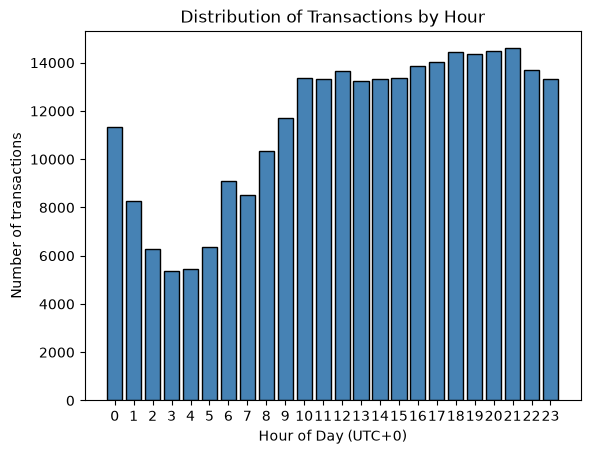

In [5]:
# 1. Query raw transaction history for the validated address list
placeholders = ','.join(['%s'] * len(addresses))
query = f"""
    SELECT DISTINCT ti.txid, ti.input_order, ti.address, bd.mempool_entry_time, 
           bd.fee, bd.num_inputs, bd.num_outputs, ti.value 
    FROM tx_inputs AS ti
    LEFT JOIN blockchain_data AS bd on ti.txid = bd.txid
    WHERE address in ({placeholders});
"""
cursor.execute(query, addresses)
database = pd.DataFrame(cursor.fetchall(), columns=["txid", "input_order", "address", "mempool_entry_time", "fee", "num_inputs", "num_outputs", "value"])

# 2. Merge entity metadata (timezone, offset) onto transaction data
db_final = database.merge(data, how="left", on="address")

# 3. Standardize Time to UTC+0
# Adjust the local mempool entry time by the user's specific geographic offset
db_final["time_adjusted"] = db_final.apply(
    lambda r: r["mempool_entry_time"] + pd.Timedelta(hours=r["offset"]),
    axis=1
)
db_final = db_final.drop_duplicates(subset=["txid"])

# Tag transactions occurring during standard Summer Time (April - October)
db_final["summer_time"] = db_final["time_adjusted"].dt.month.between(4, 10).astype("int8")

# EDA: Global Distribution of Transactions by Hour
counts, bins, patches = plt.hist(db_final[db_final["is_regional_location"] == 0]["time_adjusted"].dt.hour, 
                                 bins=np.arange(25), rwidth=0.8, color='steelblue', edgecolor='black')
plt.xticks(np.arange(24) + 0.5, labels=range(24))
plt.title("Distribution of Transactions by Hour")
plt.xlabel("Hour of Day (UTC+0)")
plt.ylabel("Number of transactions")
plt.show()

### 4: Diurnal Feature Engineering & Bayesian Normalization

Transforms raw timestamps into a continuous 24-hour activity distribution. To prevent extreme volatility caused by data sparsity (hours with 0 transactions), we apply Laplace smoothing (Bayesian Normalization).

In [6]:
# Extract the hour component from the adjusted timestamps
db_final["hour"] = pd.to_datetime(db_final["mempool_entry_time"]).dt.hour

# Pivot transactions into a 24-hour frequency matrix per entity
pivot = db_final.pivot_table(
    index=["entity", "offset", "is_regional_location"],
    columns="hour",
    values="txid",
    aggfunc="count",
    fill_value=0
)
table = pivot.reset_index()
table.columns.name = None

# Calculate absolute transaction volume
cols_to_sum = list(range(24))
table["total"] = table[cols_to_sum].sum(axis=1)
table["log_total"] = table["total"].apply(lambda r: np.log(r))

# Apply Bayesian Normalization (Laplace Smoothing)
# Formula: (X_i + alpha) / (N + 24 * alpha), mitigating the impact of zero-frequency bins
alpha = 1
table[cols_to_sum] = (table[cols_to_sum] + alpha).div(table["total"] + 24 * alpha, axis=0)

# Extract Structural Inactivity (Sleep Cycle)
# Identifies the center of the minimum 5-hour rolling activity window
hourly_data = table[cols_to_sum]
circular_data = pd.concat([hourly_data, hourly_data.iloc[:, :4]], axis=1) # Wrap-around for midnight boundary
rolling_sums = circular_data.T.rolling(window=5).sum().T

hours = (rolling_sums.iloc[:, 4:].idxmin(axis=1).astype(int) - 2) % 24
table["min_5h_activity"] = hours
table["min_5h_activity_sin"] = np.sin(hours * np.pi / 12) # Cyclical encoding
table["min_5h_activity_cos"] = np.cos(hours * np.pi / 12)
table["min_5h_activity_%"] = rolling_sums.iloc[:, 4:].min(axis=1)

### 5: Supplementary Behavioral Features (Lifespan & Subsets)

Calculates the chronological lifespan of the entity and splits the transactional activity into distinct weekday and weekend vectors to capture lifestyle deviations.

In [7]:
# 1. Entity Lifespan
lifespan_df = db_final.groupby('entity').agg(
    first_tx=('mempool_entry_time', 'min'),
    last_tx=('mempool_entry_time', 'max')
).reset_index()
lifespan_df['lifespan_days'] = (lifespan_df['last_tx'] - lifespan_df['first_tx']).dt.total_seconds() / 86400
table = table.merge(lifespan_df[["entity", "lifespan_days"]], how="left", on="entity")

# 2. Weekday vs. Weekend Segmentation
db_final["day_type"] = np.where(db_final["mempool_entry_time"].dt.dayofweek < 5, "weekday", "weekend")

table_weekday_weekend = db_final.pivot_table(
    index=["entity", "offset", "day_type"],
    columns="hour",
    values="txid",
    aggfunc="count",
    fill_value=0
).reset_index()

# Apply Laplace Smoothing to the sub-segmented data
table_weekday_weekend["total"] = table_weekday_weekend[cols_to_sum].sum(axis=1)
table_weekday_weekend["log_total"] = table_weekday_weekend["total"].apply(lambda r: np.log(r) if r > 0 else 0)
table_weekday_weekend[cols_to_sum] = (table_weekday_weekend[cols_to_sum] + alpha).div(table_weekday_weekend["total"] + 24 * alpha, axis=0)

# Unstack day type into a wide format for machine learning ingestion
df_unstacked = table_weekday_weekend.set_index(['entity', 'offset', 'day_type']).unstack('day_type')
df_unstacked.columns = [f"{str(hour)}_{day}" for hour, day in df_unstacked.columns]
df_wide = df_unstacked.reset_index().fillna(0)

### 6: Daylight Saving Time (DST) Shift Calculation

Evaluates the shift in the minimum 5-hour activity window between the defined summer and winter periods. As noted in the thesis, this metric suffers from severe data sparsity when transaction volume is low.

In [8]:
# Pivot to find the minimum 5-hour activity window during Summer (1) vs Winter (0)
table_summer_winter = db_final.pivot_table(
    index=["entity", "offset", "summer_time"],
    columns="hour",
    values="txid",
    aggfunc="count",
    fill_value=0
).reset_index()

# Apply Laplace Smoothing
table_summer_winter["total"] = table_summer_winter[cols_to_sum].sum(axis=1)
table_summer_winter["log_total"] = table_summer_winter["total"].apply(lambda r: np.log(r) if r > 0 else 0)
table_summer_winter[cols_to_sum] = (table_summer_winter[cols_to_sum] + alpha).div(table_summer_winter["total"] + 24 * alpha, axis=0)

# Calculate Seasonal Inactivity Window
hourly_data_sw = table_summer_winter[cols_to_sum]
circular_data_sw = pd.concat([hourly_data_sw, hourly_data_sw.iloc[:, :4]], axis=1)
rolling_sums_sw = circular_data_sw.T.rolling(window=5).sum().T
table_summer_winter["min_5h_activity"] = (rolling_sums_sw.iloc[:, 4:].idxmin(axis=1).astype(int) - 2) % 24

# Extract DST Shift 
dst_pivot = table_summer_winter.pivot(index="entity", columns="summer_time", values="min_5h_activity").dropna()

# Calculate raw shift (Winter - Summer) and apply circular correction
dst_pivot["dst_shift"] = dst_pivot[0] - dst_pivot[1]
dst_pivot.loc[dst_pivot["dst_shift"] > 12, "dst_shift"] -= 24
dst_pivot.loc[dst_pivot["dst_shift"] < -12, "dst_shift"] += 24

dst_features = dst_pivot[["dst_shift"]].reset_index()
dst_features.columns.name = None

### 7: Final Data Assembly and Structural Filtration

Merges the engineered behavioral metrics and restricts the dataset based on volume thresholds to guarantee robust circadian rhythm signals.

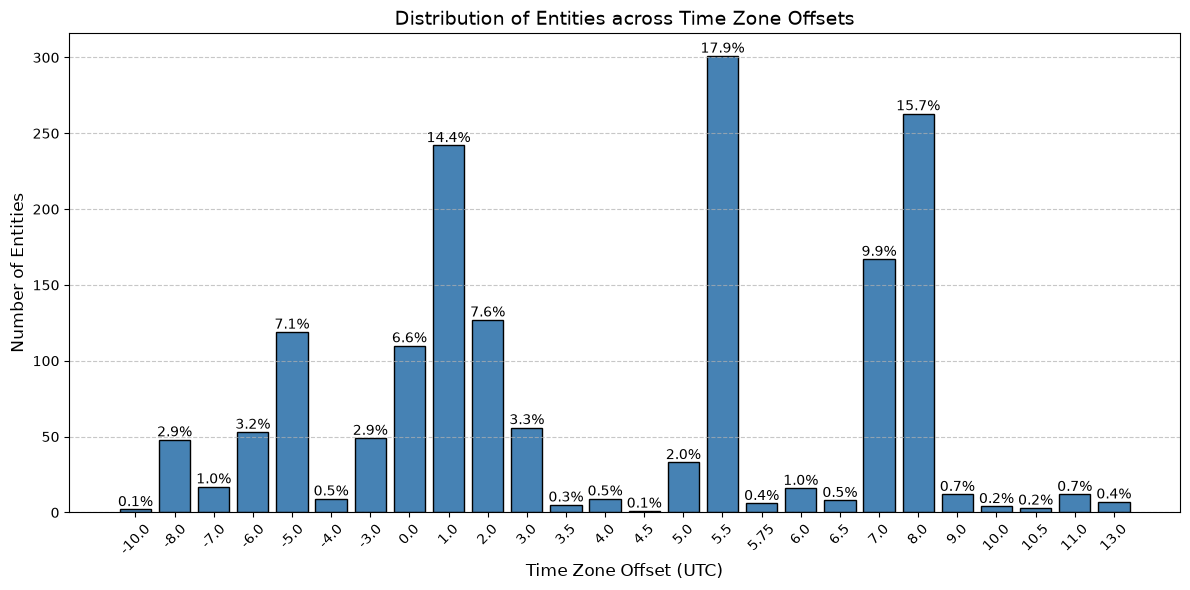

In [9]:
# 1. Merge all supplementary features into the master table
table = table.merge(df_wide, how="left", on=["entity", "offset"])
table = table.merge(dst_features, on="entity", how="left")

final_table = table.copy()

# 2. Minimum/Maximum Transaction Filtration
# Removes excessively sparse retail wallets and extremely active algorithmic/institutional wallets
table = final_table[(final_table["total"] >= 15) & (final_table["total"] <= 10000)]

# EDA: Visualize the Distribution of Entities Across Global Time Zones
offset_counts = table[table["is_regional_location"] == 0]['offset'].value_counts().sort_index()
total_entities = len(table[table["is_regional_location"] == 0])

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(offset_counts.index.astype(str), offset_counts.values, color='steelblue', edgecolor='black')

# Annotate bars with percentage distribution
for bar in bars:
    count = bar.get_height()
    percentage = (count / total_entities) * 100
    ax.text(
        bar.get_x() + bar.get_width() / 2, 
        count, 
        f'{percentage:.1f}%', 
        ha='center', va='bottom', fontsize=10
    )

plt.title('Distribution of Entities across Time Zone Offsets', fontsize=14)
plt.xlabel('Time Zone Offset (UTC)', fontsize=12)
plt.ylabel('Number of Entities', fontsize=12)
plt.xticks(rotation=45) 
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 8: Individual Time Zone Analysis & Grouping Rationale

Before applying a regional mapping, we first evaluate the average 24-hour transaction activity across the most populated individual UTC offsets. Visual inspection of these top offsets reveals strong structural similarities in the circadian rhythms of neighboring time zones. Furthermore, many minor time zones suffer from severe data sparsity. 

To mitigate this sparsity and allow the machine learning model to learn generalized, robust patterns, this step provides the empirical justification for aggregating individual offsets into broader, contiguous macro-regions.

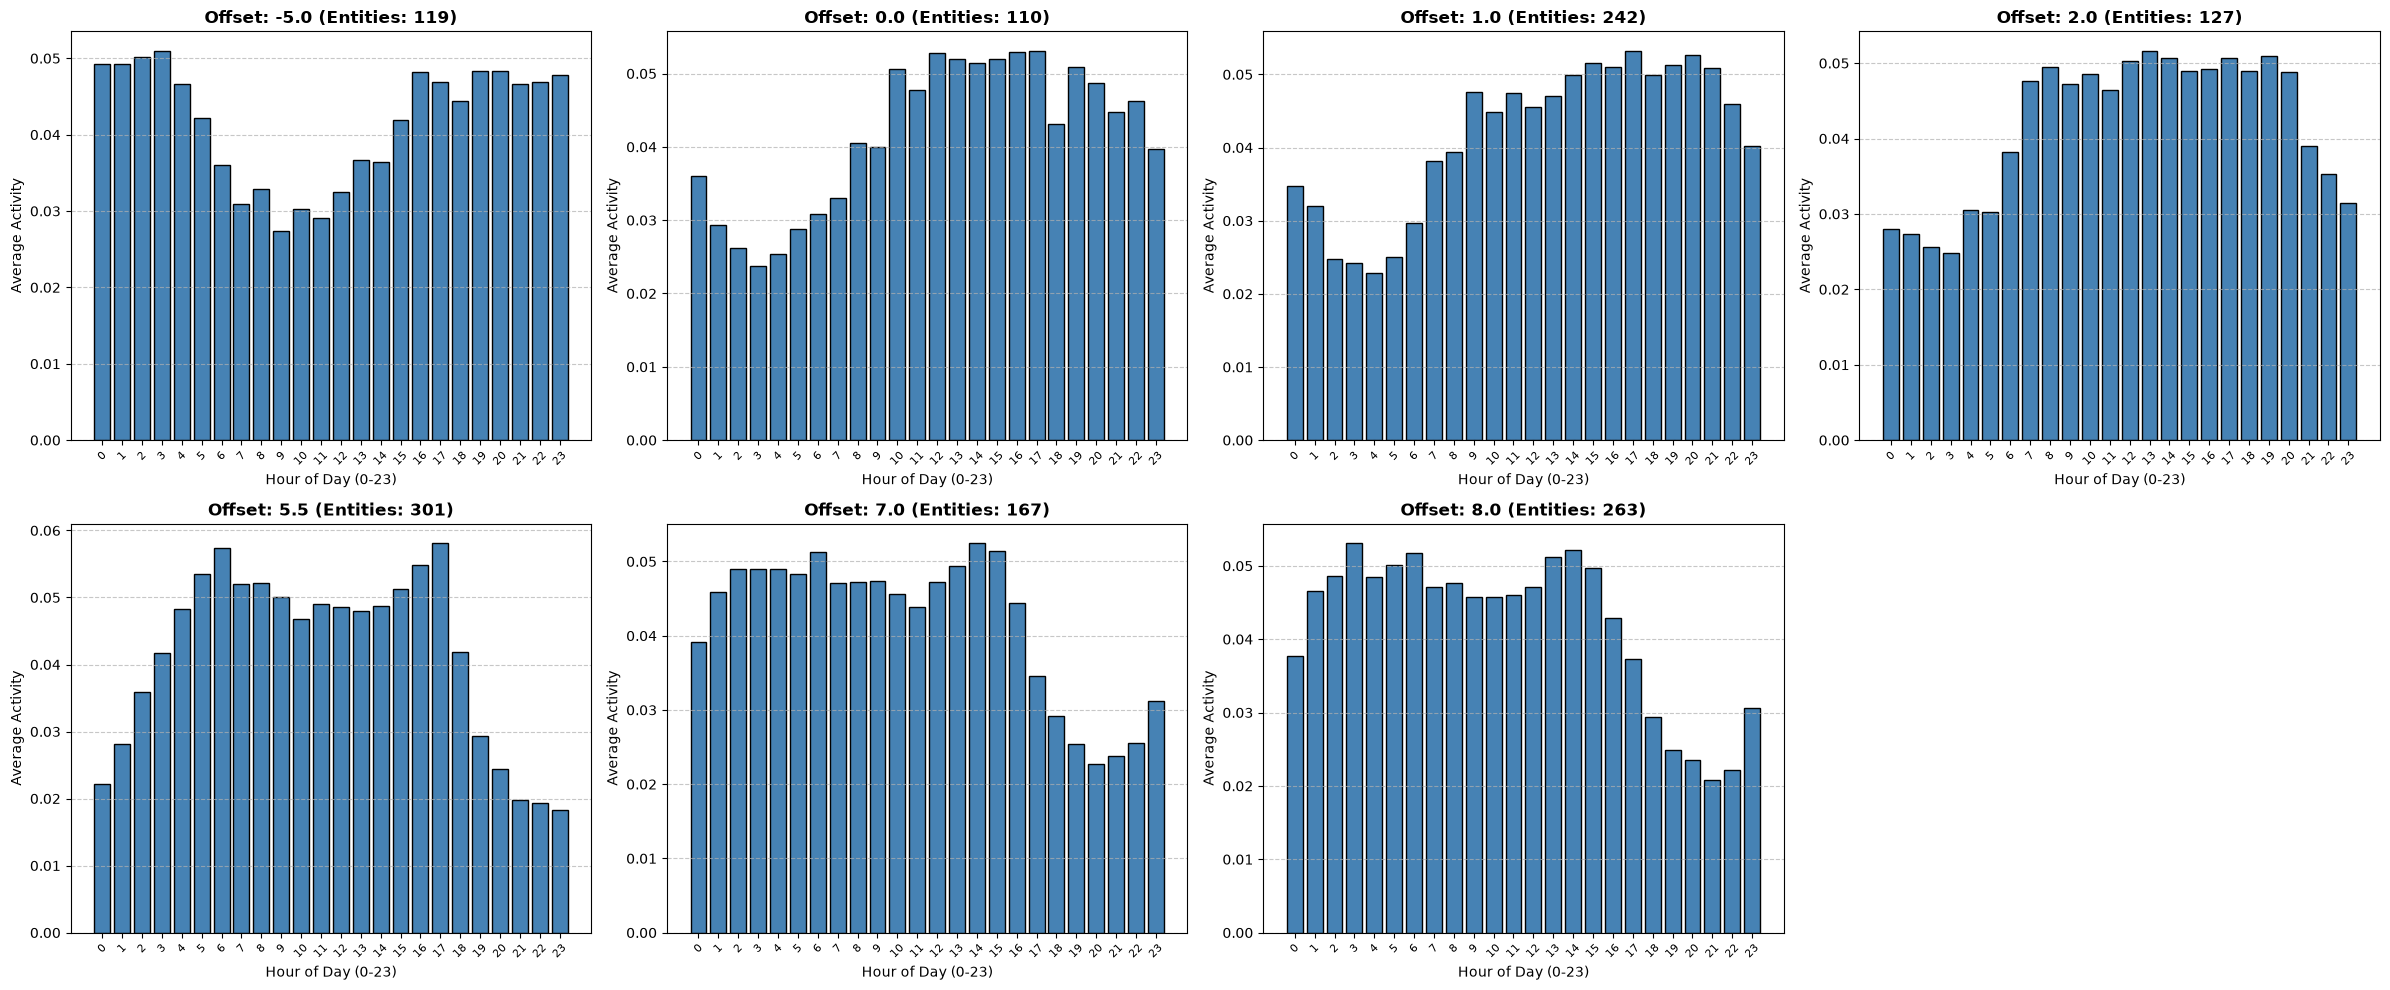

In [10]:
# 1. Find the top 7 largest offsets by entity count, then sort them by the offset value
top_7_offsets = table[table["is_regional_location"] == 0]['offset'].value_counts().nlargest(7).sort_index()

# 2. Identify the hour columns (0 to 23)
activity_cols = [col for col in table.columns if str(col).isdigit() and 0 <= int(col) <= 23]
activity_cols = sorted(activity_cols, key=lambda x: int(x))

# 3. Create a single figure with a 2x4 grid (2 rows, 4 columns)
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(24, 10))
axes = axes.flatten() # Flatten the 2D array of axes for easier looping

# 4. Loop through the sorted top 7 offsets and plot their average activity
for i, (offset_val, count) in enumerate(top_7_offsets.items()):
    ax = axes[i]
    
    # Filter data for the current offset
    subset = table[table['offset'] == offset_val]
    
    # Calculate the AVERAGE (mean) across the 0-23 columns
    avg_activity = subset[activity_cols].mean()
    
    # Plot as a bar chart to show the distribution
    ax.bar(avg_activity.index.astype(str), avg_activity.values, color='steelblue', edgecolor='black')
    
    # Add title with the offset value and the exact number of entities
    ax.set_title(f'Offset: {offset_val} (Entities: {count})', fontsize=12, fontweight='bold')
    ax.set_xlabel('Hour of Day (0-23)', fontsize=10)
    ax.set_ylabel('Average Activity', fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    ax.tick_params(axis='x', rotation=45, labelsize=8)

# 5. Hide the 8th (unused) subplot since we only need 7 graphs
axes[7].set_visible(False)

# 6. Adjust spacing and render
plt.tight_layout()
plt.show()

### 9: Macro-Region Mapping & Visualization

Based on the similarities observed in Phase 8, continuous UTC offsets are aggregated into four distinct macro-regions: Americas, Euro-Africa, Central & South Asia, and East Asia & Pacific. This phase extracts summary statistics for each region and visualizes their respective consolidated activity histograms.

/tmp/ipykernel_39356/984105752.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  table['region'] = table['offset'].map(region_mapping)


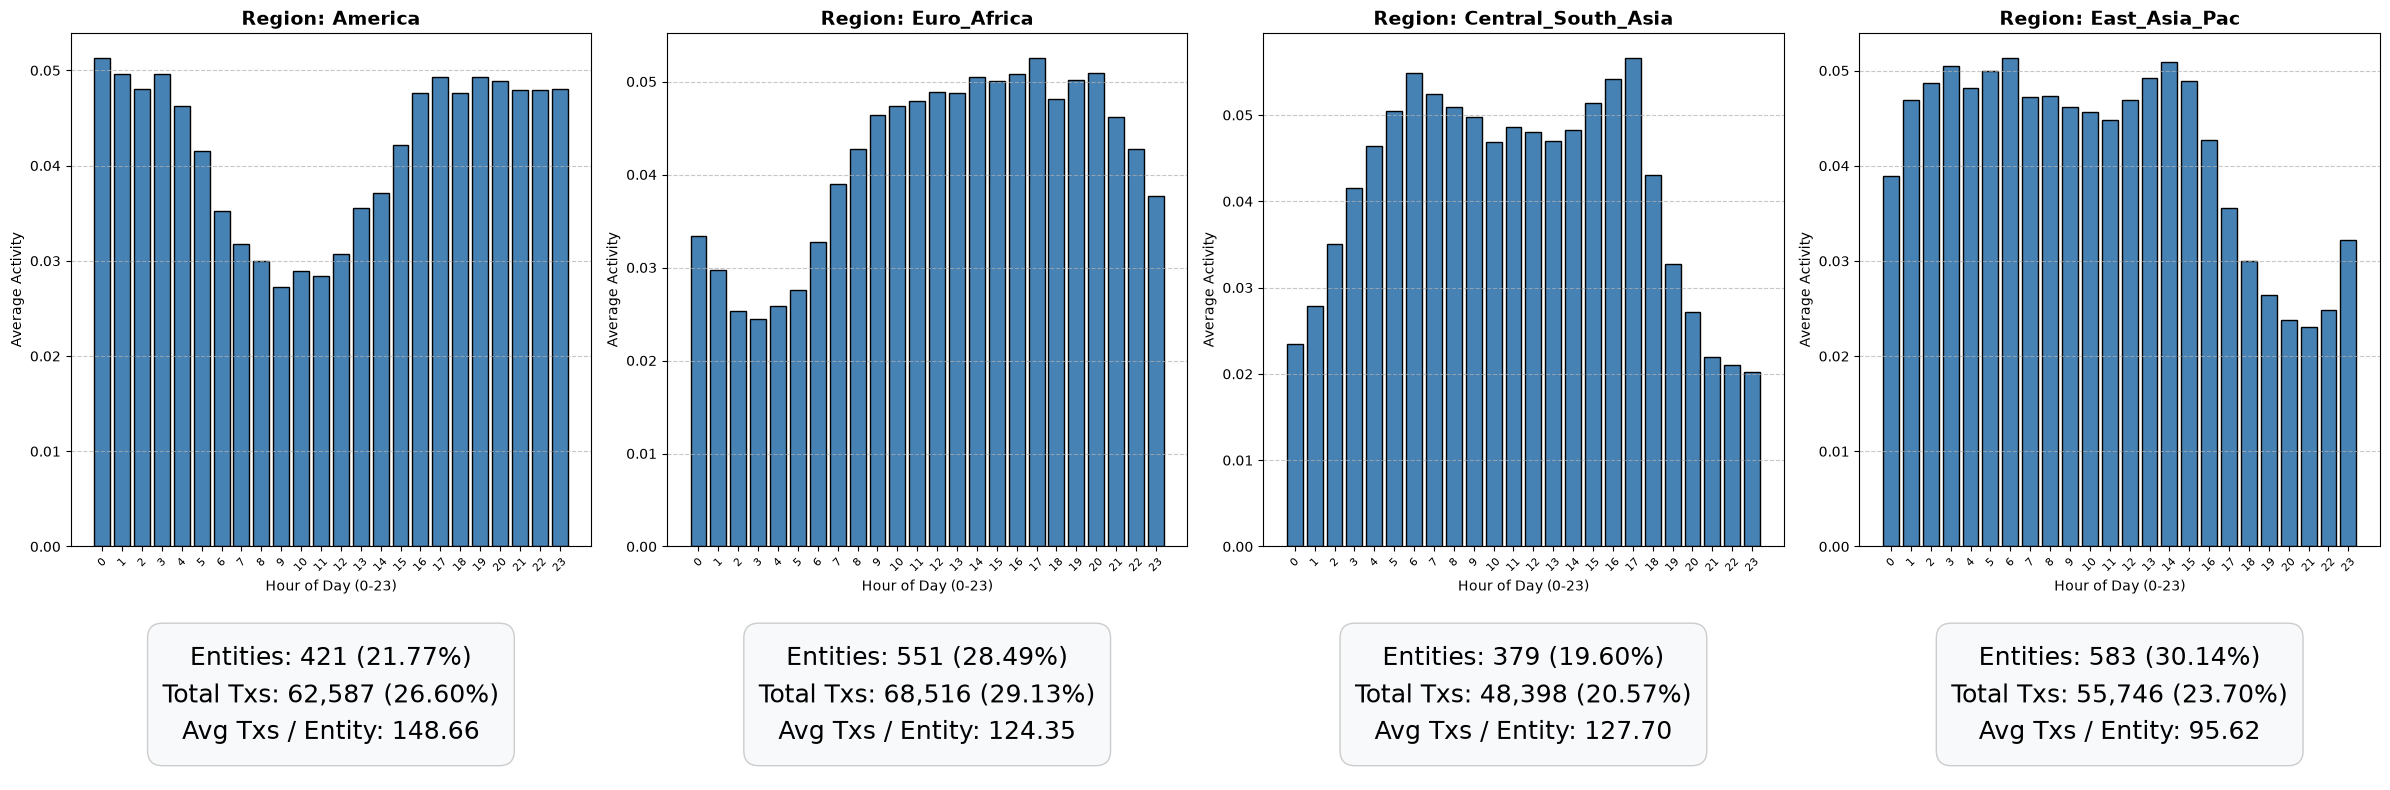

In [ ]:
# 1. Macro-Region Mapping
region_mapping = {
    # America
    -8.0: 'America', -7.0: 'America', -6.0: 'America', 
    -5.0: 'America', -4.0: 'America', -3.0: 'America',
    
    # Euro-Africa
    0.0: 'Euro_Africa', 1.0: 'Euro_Africa', 2.0: 'Euro_Africa', 3.0: 'Euro_Africa',
    
    # Central Asia / India / Middle East
    3.5: 'Central_South_Asia', 4.0: 'Central_South_Asia', 4.5: 'Central_South_Asia', 
    5.0: 'Central_South_Asia', 5.5: 'Central_South_Asia', 5.75: 'Central_South_Asia', 
    6.0: 'Central_South_Asia', 6.5: 'Central_South_Asia',
    
    # East Asia / Pacific
    7.0: 'East_Asia_Pac', 8.0: 'East_Asia_Pac', 9.0: 'East_Asia_Pac', 
    10.0: 'East_Asia_Pac', 10.5: 'East_Asia_Pac', 11.0: 'East_Asia_Pac', 
    12.0: 'East_Asia_Pac', 13.0: 'East_Asia_Pac', -10.0: 'East_Asia_Pac', -9.0: 'East_Asia_Pac',
}

table['region'] = table['offset'].map(region_mapping)

# 2. Data Preparation & Summary Statistics
total_entities_all = len(table)
total_txs_all = table['total'].sum()

summary_table = table.groupby('region').agg(
    number_of_entities=('entity', 'count'),
    number_of_txs=('total', 'sum')
).reset_index()

summary_table['avg_txs_per_entity'] = summary_table['number_of_txs'] / summary_table['number_of_entities']
summary_table['entity_percentage'] = (summary_table['number_of_entities'] / total_entities_all) * 100
summary_table['txs_percentage'] = (summary_table['number_of_txs'] / total_txs_all) * 100
summary_table = summary_table.round({'avg_txs_per_entity': 2, 'entity_percentage': 2, 'txs_percentage': 2})

# 3. Visualization: Histograms with Summary Stats
desired_order = ['America', 'Euro_Africa', 'Central_South_Asia', 'East_Asia_Pac']
regions_to_plot = [r for r in desired_order if r in table['region'].values]

fig, axes = plt.subplots(
    nrows=2, 
    ncols=len(regions_to_plot), 
    figsize=(24, 8), 
    gridspec_kw={'height_ratios': [3, 1]}
)

for i, region in enumerate(regions_to_plot):
    ax_chart = axes[0, i]
    ax_stats = axes[1, i]
    
    # Filter and calculate average hourly activity
    subset = table[table['region'] == region]
    avg_activity = subset[activity_cols].mean()
    reg_stats = summary_table[summary_table['region'] == region].iloc[0]
    
    # Top Row: Average Activity Histogram
    ax_chart.bar(avg_activity.index.astype(str), avg_activity.values, color='steelblue', edgecolor='black')
    ax_chart.set_title(f'Region: {region}', fontsize=14, fontweight='bold')
    ax_chart.set_xlabel('Hour of Day (0-23)', fontsize=10)
    ax_chart.set_ylabel('Average Activity', fontsize=10)
    ax_chart.grid(axis='y', linestyle='--', alpha=0.7)
    ax_chart.tick_params(axis='x', rotation=45, labelsize=8)
    
    # Bottom Row: Summary Text Box
    ax_stats.axis('off')
    stats_text = (
        f"Entities: {int(reg_stats['number_of_entities']):,} ({reg_stats['entity_percentage']:.2f}%)\n"
        f"Total Txs: {int(reg_stats['number_of_txs']):,} ({reg_stats['txs_percentage']:.2f}%)\n"
        f"Avg Txs / Entity: {reg_stats['avg_txs_per_entity']:.2f}"
    )
    
    ax_stats.text(
        0.5, 0.5, stats_text,
        transform=ax_stats.transAxes,
        fontsize=18,
        ha='center', va='center', linespacing=1.5,
        bbox=dict(boxstyle='round,pad=0.6', facecolor='#f8f9fa', edgecolor='#cccccc', linewidth=1)
    )

plt.tight_layout()
plt.show()

### 10: Final Dataset Export

The fully engineered, smoothed, and macro-region mapped dataset is serialized to a CSV file. This provides a clean, reproducible input vector for the hyperparameter tuning and XGBoost classification model pipelines.

In [12]:
# Export the DataFrame to CSV 
table.to_csv("database_from_bitcointalk.csv")

print(f"✅ Processing Complete.")
print(f"📊 Total Entities Ready for ML: {total_entities_all}")
print(f"📉 Total Features Engineered: {len(table.columns)}")

✅ Processing Complete.
📊 Total Entities Ready for ML: 1934
📉 Total Features Engineered: 88
